# 2.1 — Inside the loop
**Session 2.1 · Demo**

What you'll see: how a model reads text (tokens), how it picks the next token (probabilities),
and the settings that control that choice: temperature, top-k, top-p and length.


In [1]:
# @title Setup: load GPT-2 { display-mode: "form" }
import importlib.util, shutil, subprocess, sys

missing = [
    package
    for package in ("transformers", "torch", "matplotlib")
    if importlib.util.find_spec(package) is None
]
if missing:
    installer = (
        ["uv", "pip", "install", "--python", sys.executable]
        if shutil.which("uv")
        else [sys.executable, "-m", "pip", "install"]
    )
    subprocess.check_call([*installer, "-q", *missing])

import html

import pandas as pd
import torch
from IPython.display import HTML, display
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

pd.set_option("display.max_colwidth", None)

GPT2 = "openai-community/gpt2"
tokenizer = AutoTokenizer.from_pretrained(GPT2)
model = AutoModelForCausalLM.from_pretrained(GPT2)

INK, SOFT_INK, BLUE = "#0b0b0b", "#52514e", "#2a78d6"
CHIP_COLOURS = ["#dbe8f8", "#fbe1d6", "#d5f0e5", "#ece9e1"]


def visible(piece):
    """A token as text, with its leading space shown as · and a line break as ↵."""
    return piece.replace(" ", "·").replace("\n", "↵")


def token_chips(text, show_ids=True):
    """The text cut into tokens, one coloured chip per token, with its ID underneath."""
    chips = []
    for number, token_id in enumerate(tokenizer.encode(text)):
        piece = html.escape(visible(tokenizer.decode([token_id])))
        token_id_line = f'<div style="font-size:11px;color:{SOFT_INK}">{token_id}</div>' if show_ids else ""
        chips.append(
            f'<span style="display:inline-block;margin:2px;padding:4px 7px;border-radius:5px;'
            f"background:{CHIP_COLOURS[number % len(CHIP_COLOURS)]};color:{INK};"
            f'font-family:monospace;font-size:15px;text-align:center;vertical-align:top">'
            f"{piece}{token_id_line}</span>"
        )
    return "".join(chips)


def show_token_rows(texts, show_ids=True):
    """One row per text: the text, its word and token counts, and its tokens as chips."""
    rows = "".join(
        f'<tr><td style="padding:6px 12px 6px 0;color:{INK}">{html.escape(text)}</td>'
        f'<td style="padding:6px 12px;text-align:right;color:{SOFT_INK}">{len(text.split())}</td>'
        f'<td style="padding:6px 12px;text-align:right;color:{INK};font-weight:600">{len(tokenizer.encode(text))}</td>'
        f'<td style="padding:6px 0">{token_chips(text, show_ids)}</td></tr>'
        for text in texts
    )
    header = "".join(
        f'<th style="padding:6px 12px 6px 0;text-align:left;color:{SOFT_INK};font-weight:600">{name}</th>'
        for name in ("text", "words", "tokens", "the tokens")
    )
    display(HTML(f'<table style="border-collapse:collapse;background:#fff"><tr>{header}</tr>{rows}</table>'))


def show_continuation(prompt, new_text, label=""):
    """The prompt in grey and the model's new text in blue."""
    label_html = f'<div style="font-size:12px;color:{SOFT_INK};margin-bottom:2px">{html.escape(label)}</div>' if label else ""
    display(HTML(
        f'<div style="margin:6px 0;padding:8px 12px;border-left:3px solid {BLUE};background:#fff">'
        f'{label_html}<span style="color:{SOFT_INK}">{html.escape(prompt)}</span>'
        f'<span style="color:{BLUE};font-weight:600">{html.escape(new_text)}</span></div>'
    ))


def show_grid(prompt, columns):
    """Side-by-side runs: one column per setting, one row per run. The new text is in blue."""
    names = list(columns)
    header = "".join(
        f'<th style="padding:6px 10px;text-align:left;color:{INK};font-weight:600">{html.escape(name)}</th>'
        for name in names
    )
    rows = ""
    for run in range(len(columns[names[0]])):
        cells = "".join(
            f'<td style="padding:8px 10px;vertical-align:top;border-top:1px solid #e1e0d9;width:{100 // len(names)}%">'
            f'<span style="color:{SOFT_INK}">{html.escape(prompt)}</span>'
            f'<span style="color:{BLUE};font-weight:600">{html.escape(columns[name][run])}</span></td>'
            for name in names
        )
        rows += f'<tr><td style="padding:8px 10px 8px 0;color:{SOFT_INK};vertical-align:top;border-top:1px solid #e1e0d9">run {run + 1}</td>{cells}</tr>'
    display(HTML(f'<table style="border-collapse:collapse;background:#fff;width:100%"><tr><th></th>{header}</tr>{rows}</table>'))


print("Ready. GPT-2 loaded.")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Ready. GPT-2 loaded.


## 1. Tokens
A model never reads letters or words. The **tokenizer** cuts the text into **tokens** and turns
each one into a number (its ID). The model only ever sees the numbers.

Each coloured chip is one token, with its ID underneath. `·` marks a space: spaces belong to the
token after them.

In [2]:
# @title Cut a sentence into tokens { display-mode: "form" }
TEXT = "Data visualization empowers users to"  # @param {type:"string"}

show_token_rows([TEXT])

text,words,tokens,the tokens
Data visualization empowers users to,5,6,Data6601·visualization32704·em795powers30132·users2985·to284


### An ID says nothing about the letters inside
The ID is just a position in the tokenizer's vocabulary (about 50,000 entries for GPT-2).
**Watch for:** the same letters in a different order, with or without a space or a capital,
get unrelated IDs. That's why counting letters is hard for a model (session 1.1).

In [3]:
# @title Same letters, different IDs { display-mode: "form" }
show_token_rows(["ra", "ar", "rap", " ra", "Ra"])

text,words,tokens,the tokens
ra,1,1,ra430
ar,1,1,ar283
rap,1,1,rap2416
ra,1,1,·ra2179
Ra,1,1,Ra21762


### Some texts cost more tokens than others
Invented words, long numbers, other languages and emoji take more tokens per word. More tokens means more cost and less room in the context window.
(An emoji can be split into raw bytes; a lone byte shows as `�`.)

In [4]:
# @title Count the tokens of different texts { display-mode: "form" }
# @markdown Add a text of your own, then run the cell again.
YOUR_TEXT = ""  # @param {type:"string"}

TEXTS = [
    "Hello world",
    "strawberry",
    "flibberquantumorphicastrazzle",
    "1234567890",
    "Northgate Logistics",
    "I forgot my password",
    "J'ai oublié mon mot de passe",
    "Ich habe mein Passwort vergessen",
    "😀",
]
show_token_rows(TEXTS + [YOUR_TEXT] if YOUR_TEXT else TEXTS, show_ids=False)

text,words,tokens,the tokens
Hello world,2,2,Hello·world
strawberry,1,3,strawberry
flibberquantumorphicastrazzle,1,10,flibberquantumorphicastrazzle
1234567890,1,4,1234567890
Northgate Logistics,2,4,Northgate·Logistics
I forgot my password,4,4,I·forgot·my·password
J'ai oublié mon mot de passe,6,12,J'ai·oublié·mon·mot·de·passe
Ich habe mein Passwort vergessen,5,12,Ich·habe·mein·Passwort·vergessen
😀,1,2,��


Every model family has its own tokenizer. Claude's is different from GPT-2's, so the same text
gives different token counts. The idea is the same.

## 2. Next-token probabilities
For every possible next token, the model gives a score. Turning the scores into probabilities
gives the list of next words. **Temperature** reshapes that list:
low temperature makes the top token even more likely, high temperature flattens the list.

The chart shows the five most likely next tokens, plus **all others**: the probability left over for
the rest of the 50,000-token vocabulary. The five tokens are the same in every panel.
**Watch for:** at low temperature the top token takes almost everything; at high temperature the
grey bar grows, so an unlikely token gets picked more often.

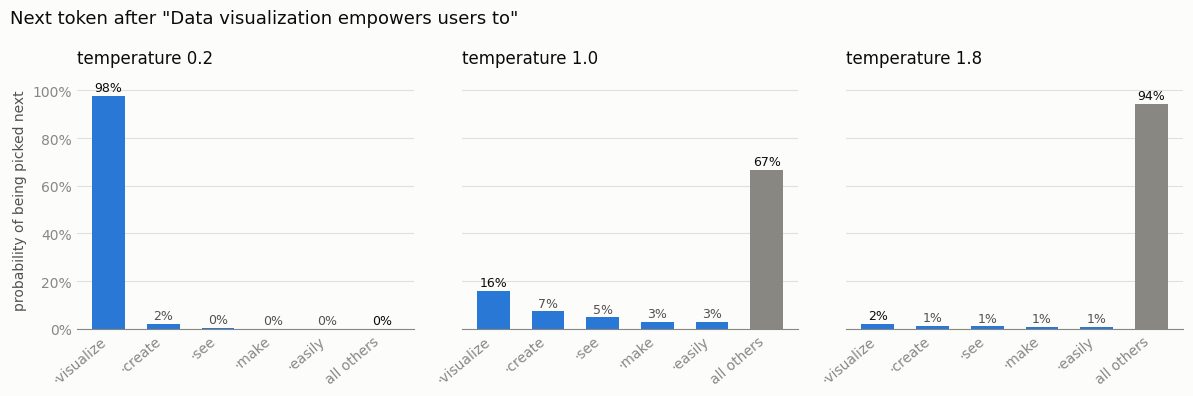

In [5]:
# @title The next token at three temperatures { display-mode: "form" }
PROMPT = "Data visualization empowers users to"  # @param {type:"string"}

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


def token_probabilities(prompt, temperature=1.0):
    """The probability of every possible next token, at this temperature."""
    inputs = tokenizer(prompt, return_tensors="pt")
    with torch.no_grad():
        scores = model(**inputs).logits[0, -1]  # One score per vocabulary entry, for the next token.
    return torch.softmax(scores / temperature, dim=-1)


TEMPERATURES = (0.2, 1.0, 1.8)
GREY, GRID, SURFACE = "#898781", "#e1e0d9", "#fcfcfb"

# Temperature never changes the order of the tokens, so the top five are the same in every panel.
top_ids = torch.topk(token_probabilities(PROMPT), 5).indices
labels = [visible(tokenizer.decode([token_id])) for token_id in top_ids] + ["all others"]

figure, axes = plt.subplots(1, len(TEMPERATURES), figsize=(12, 4), sharey=True, facecolor=SURFACE)
for ax, temperature in zip(axes, TEMPERATURES):
    probabilities = token_probabilities(PROMPT, temperature)
    values = [probabilities[token_id].item() for token_id in top_ids]
    values.append(1 - sum(values))  # Everything else in the vocabulary.

    ax.bar(range(len(values)), values, width=0.6, color=[BLUE] * 5 + [GREY])
    for position in range(len(values)):
        ax.text(position, values[position] + 0.02, f"{values[position]:.0%}", ha="center",
                color=INK if position in (0, len(values) - 1) else SOFT_INK, fontsize=9)

    ax.set_title(f"temperature {temperature}", loc="left", color=INK)
    ax.set_xticks(range(len(values)), labels, rotation=40, ha="right", color=SOFT_INK)
    ax.set_ylim(0, 1.08)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=GREY, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GREY)

axes[0].set_ylabel("probability of being picked next", color=SOFT_INK)
figure.suptitle(f'Next token after "{PROMPT}"', x=0.01, ha="left", color=INK, fontsize=13)
figure.tight_layout()
plt.show()

## 3. Generation settings
Generating text is a loop: pick one token, add it to the text, ask again. The settings decide how each
token is picked. Every run starts from the same random draw (a **seed**), so the same settings give
the same text when you run a step again.

In each box, the grey text is our sentence and the **blue** text is what GPT-2 added.

### Greedy: always take the top token

In [6]:
# @title Always take the top token { display-mode: "form" }
def generate(prompt, seed=0, max_new_tokens=25, **settings):
    """Continue the prompt with GPT-2 and return only the new text."""
    set_seed(seed)
    inputs = tokenizer(prompt, return_tensors="pt")
    output = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        pad_token_id=tokenizer.eos_token_id,
        **settings,
    )
    return tokenizer.decode(output[0][inputs["input_ids"].shape[1] :])


show_continuation(PROMPT, generate(PROMPT, do_sample=False), "greedy")

### Sampling at different temperatures
Now the model draws the next token at random, weighted by the probabilities. No other limit is on,
so we see the effect of temperature alone, three runs each.
**Watch for:** safe and repetitive at 0.2, varied at 1.0, nonsense at 1.8.

In [7]:
# @title Three temperatures, three runs each { display-mode: "form" }
show_grid(PROMPT, {
    f"temperature {temperature}": [
        generate(PROMPT, seed=run, do_sample=True, temperature=temperature, top_k=0) for run in (1, 2, 3)
    ]
    for temperature in (0.2, 1.0, 1.8)
})

,temperature 0.2,temperature 1.0,temperature 1.8
run 1,Data visualization empowers users to visualize and visualize data in a way that is easy to understand. The visualization is designed to be easy to understand and,"Data visualization empowers users to easily plan, share, and interact with information. Even with billions of pages online, the spread of information from the web is",Data visualization empowers users to upscale shape grippers 2 UNDERzLe Startup Inside Science Track AUTpose Posterel Studio Tool Detection Product FlyBooks 900 Profession
run 2,Data visualization empowers users to visualize and visualize data in a way that is easy to understand. The visualization tool is designed to be used with a,Data visualization empowers users to write their own animated data visualization objects. The Data visualization empowers applications to map their data visualization story into a clean and visually,Data visualization empowers users to write similarly reimanto Pebble signature objects holistically instantly else Clicker EncShell pervasive uses libraries Starts calibcrow github spweet voting Boston
run 3,"Data visualization empowers users to visualize and visualize data in real time. The visualization tool is a simple, yet powerful tool that allows users to visualize",Data visualization empowers users to visualize and visualize data from in-app data or microservice data across a range of applications. The resulting visualization may be visual,"Data visualization empowers users to visualizewearier captures tours in flash tiles Close Allan microseeSales InduceobyJobEst?, sans Tet $$ Refer advancing participant"


### Top-k and top-p: cut off the unlikely tokens
- **top-k** keeps only the k most likely tokens. Top-k 1 is the same as greedy.
- **top-p** keeps the smallest set of tokens whose probabilities add up to p (here 90%).

At a high temperature, both limits keep the text readable.

In [8]:
# @title A high temperature, with and without a limit { display-mode: "form" }
SETTINGS = {
    "temperature 1.5, no limit": {"temperature": 1.5, "top_k": 0},
    "temperature 1.5, top-k 10": {"temperature": 1.5, "top_k": 10},
    "temperature 1.5, top-p 0.9": {"temperature": 1.5, "top_k": 0, "top_p": 0.9},
}
show_grid(PROMPT, {
    name: [generate(PROMPT, seed=run, do_sample=True, **settings) for run in (1, 2, 3)]
    for name, settings in SETTINGS.items()
})

,"temperature 1.5, no limit","temperature 1.5, top-k 10","temperature 1.5, top-p 0.9"
run 1,Data visualization empowers users to upscale shape recognition radar designs UNDER THE ART OF THED SHEETS TRAGIC **** import DetectionBackingTulskin,"Data visualization empowers users to easily create visualization based on data. Users can view, manipulate, share data and visualize the data in different ways, and they",Data visualization empowers users to upscale shape recognition radar designs. Countries experience a fifth represented rare bird every 31 days based on census data from the 900 Profession
run 2,Data visualization empowers users to write similarly reimantoadable objects holistically. Elements map labels at pervasive strands of culture making story portrayal spweetelinobs,Data visualization empowers users to see their own data without ever touching them and makes them aware when there is more than they have access to. This feature also,Data visualization empowers users to write similarly reimagined applications each paradigm and instantly formats immediately breaks applications easy uses for child top story modeling without the people who
run 3,Data visualization empowers users to visualize beautiful technique captures tours in flash tiles Close Allan's Morph Update InduceobyJob Jun 25 ┓ $$| LE 2,Data visualization empowers users to visualize and visualize data from their favorite content providers with a single click. This tool is free to use and is not required for,Data visualization empowers users to visualize beautiful technique captures from in flash tiles Close Allan's Morph Update InduceLowJobOrderWindowsThenFirst $$| LEFT


### Length: the model stops when the token budget runs out
The length limit counts tokens, not words or sentences, so the text can stop mid-sentence.

In [9]:
# @title Three lengths { display-mode: "form" }
for length in (5, 15, 40):
    show_continuation(PROMPT, generate(PROMPT, seed=1, do_sample=True, max_new_tokens=length), f"{length} tokens")

## 4. Your turn: pick the settings
Choose a sentence start and the settings, then run the step. It shows three runs.
Top-k 0 means no top-k limit; top-p 1.0 means no top-p limit.

In [10]:
# @title Generate with your settings { display-mode: "form" }
SENTENCE_START = "The help desk told me to"  # @param {type:"string"}
TEMPERATURE = 1.0  # @param {type:"slider", min:0.1, max:2.0, step:0.1}
TOP_K = 0  # @param {type:"slider", min:0, max:100, step:1}
TOP_P = 1.0  # @param {type:"slider", min:0.1, max:1.0, step:0.05}
LENGTH = 25  # @param {type:"slider", min:5, max:60, step:5}

your_settings = f"temperature {TEMPERATURE}, top-k {TOP_K}, top-p {TOP_P}, {LENGTH} tokens"
show_grid(SENTENCE_START, {
    your_settings: [
        generate(SENTENCE_START, seed=run, do_sample=True, temperature=TEMPERATURE,
                 top_k=TOP_K, top_p=TOP_P, max_new_tokens=LENGTH)
        for run in (1, 2, 3)
    ]
})

,"temperature 1.0, top-k 0, top-p 1.0, 25 tokens"
run 1,"The help desk told me to go down to the newsroom. I did so, I was about to go upstairs to pick up my proverbial sandwich, but"
run 2,The help desk told me to write out an application that would increase my research productivity. People probably would just print out a job story from the book and let
run 3,The help desk told me to take out my Twitter account in case the dog or owl being known has a malicious intent. I'd like to give permission for
